In [1]:
import pandas as pd

features = pd.read_csv("data/elliptic_txs_features.csv", header=None)
classes = pd.read_csv("data/elliptic_txs_classes.csv")
edges = pd.read_csv("data/elliptic_txs_edgelist.csv")

print(features.shape, classes.shape, edges.shape)
print(classes["class"].value_counts())

(203769, 167) (203769, 2) (234355, 2)
class
unknown    157205
2           42019
1            4545
Name: count, dtype: int64


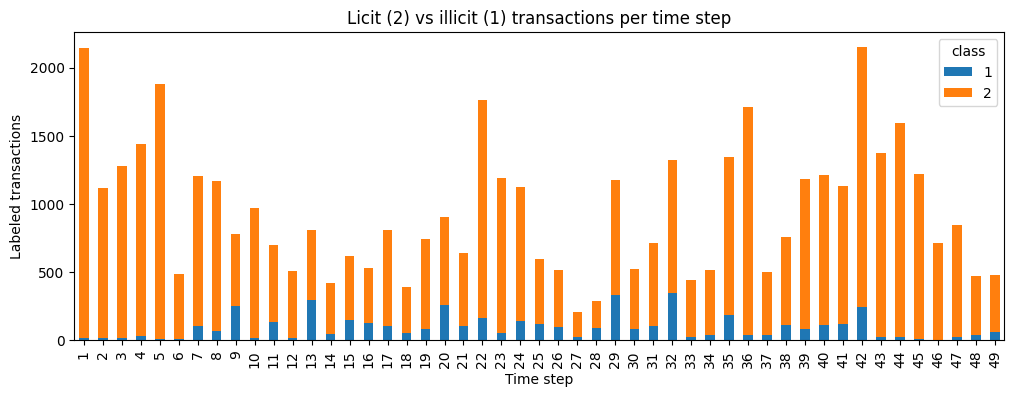

In [2]:
import matplotlib.pyplot as plt

features = features.rename(columns={0: "txId", 1: "time_step"})
classes = classes.rename(columns={"txId": "txId"})
df = features.merge(classes, on="txId")

labeled = df[df["class"] != "unknown"]
counts = labeled.groupby(["time_step", "class"]).size().unstack(fill_value=0)

counts.plot(kind="bar", stacked=True, figsize=(12, 4))
plt.xlabel("Time step")
plt.ylabel("Labeled transactions")
plt.title("Licit (2) vs illicit (1) transactions per time step")
plt.show()